WINE QUALITY PREDICTION

1. INSTALL LIBRARIES IF REQUIRED

In [41]:
pip install kagglehub[pandas-datasets] pandas numpy scikit-learn seaborn matplotlib

2. IMPORTS AND DECLARATIONS

In [42]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

3. LOADING THE DATASET

In [43]:

# Install dependencies if needed:
# pip install kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter
import os
import glob
import pandas as pd

# Load the latest dataset from Kaggle
dataset_path = kagglehub.dataset_download("yasserh/wine-quality-dataset")

# Find the actual CSV filename
csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)

print("Available dataset files:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV files found in the Kaggle dataset.")

# Load the CSV directly into a DataFrame
file_path = csv_files[0]

df = pd.read_csv(file_path)

print("\nLoaded file:", os.path.basename(file_path))

print("\nFirst 5 records:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe())

# Remove duplicate records
df = df.drop_duplicates().copy()

print("\nDataset loaded and cleaned successfully!")


Using Colab cache for faster access to the 'wine-quality-dataset' dataset.
Available dataset files: ['/kaggle/input/wine-quality-dataset/WineQT.csv']

Loaded file: WineQT.csv

First 5 records:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60

4. QUALITY SCORE DISTRIBUTION AND CLASS IMBALANCE


Original quality score distribution:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


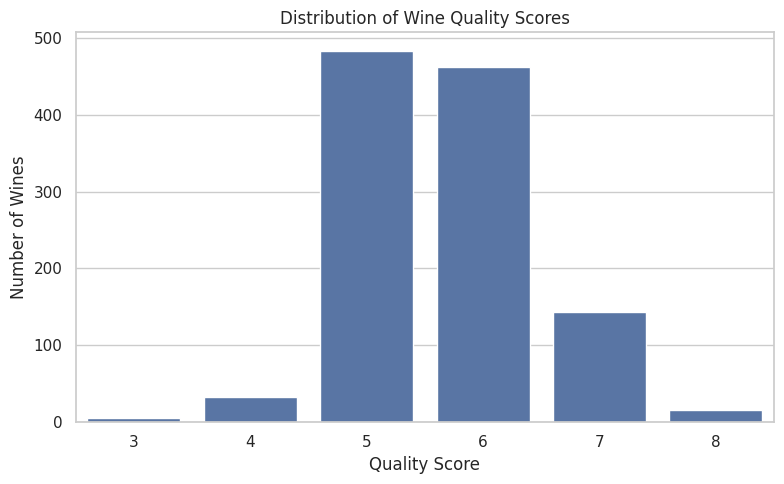


Original class percentages:
quality
3     0.52
4     2.89
5    42.26
6    40.42
7    12.51
8     1.40
Name: proportion, dtype: float64


In [44]:
print("\nOriginal quality score distribution:")
print(df["quality"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

print("\nOriginal class percentages:")
print(
    (df["quality"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

5. EXPLORATORY DATA ANALYSIS

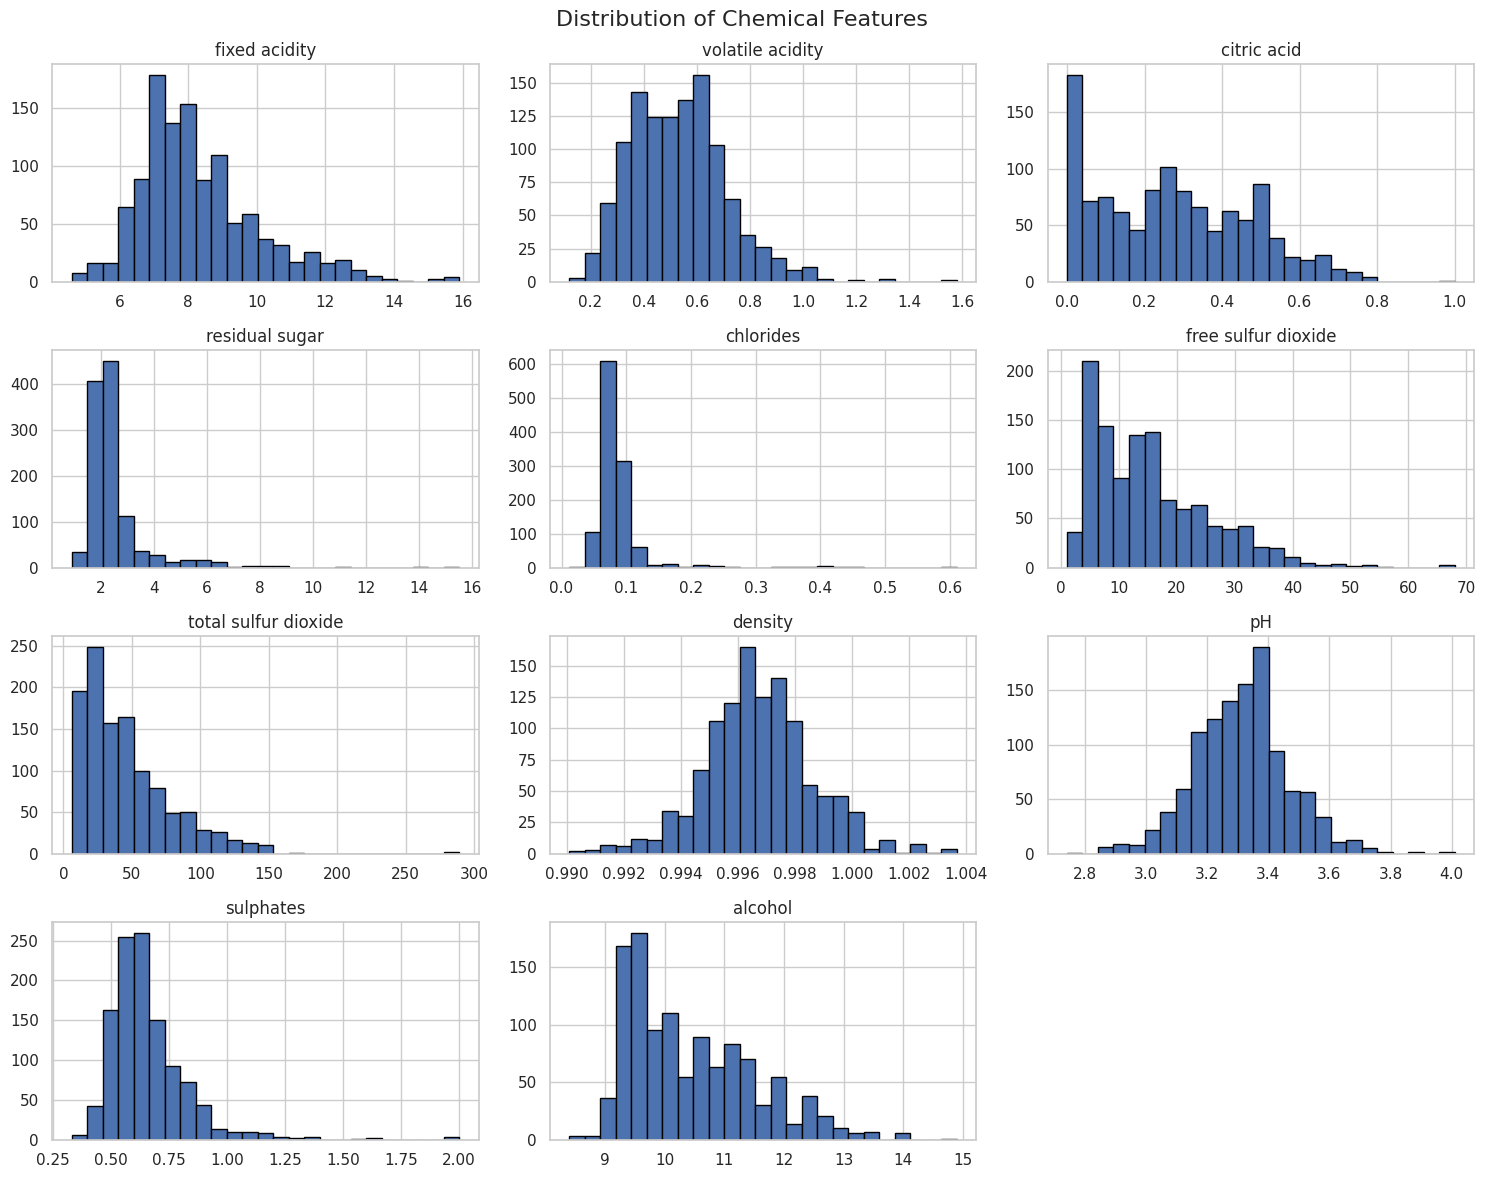

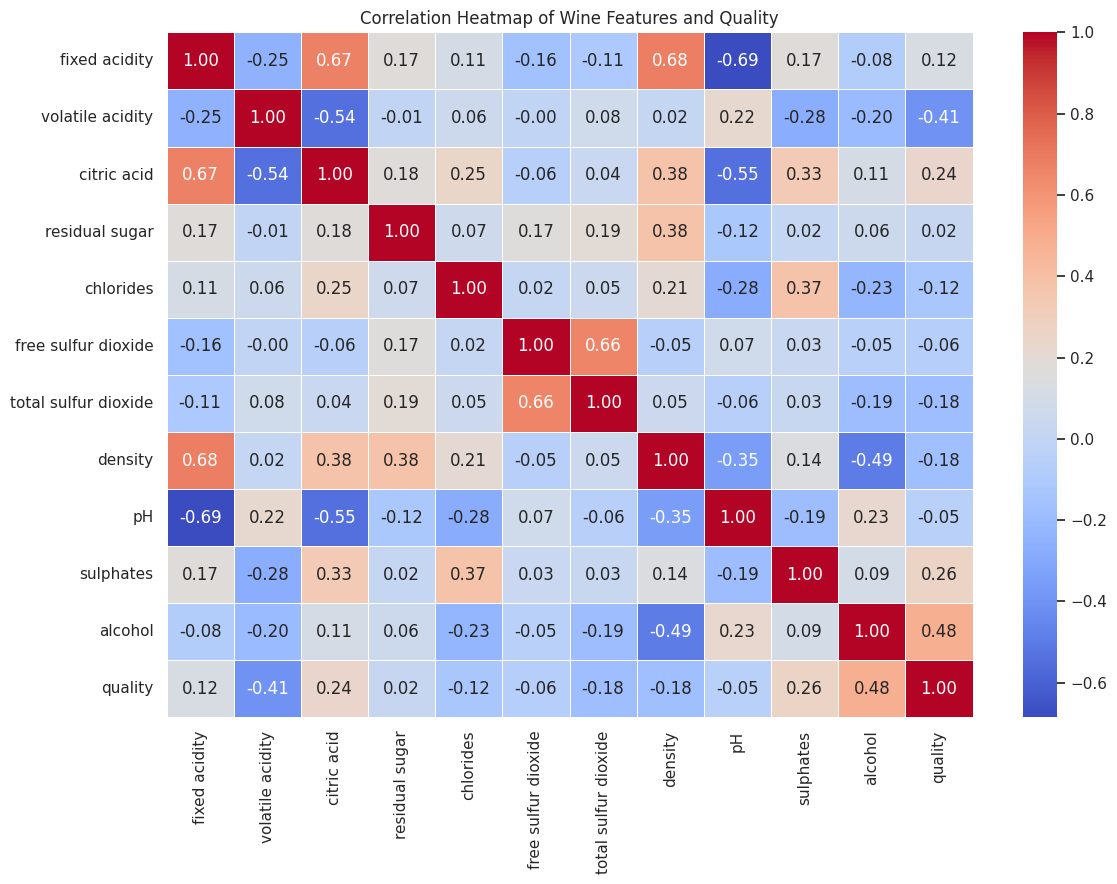


Correlation with original quality score:
quality                 1.000000
alcohol                 0.484866
sulphates               0.257710
citric acid             0.240821
fixed acidity           0.121970
residual sugar          0.022002
pH                     -0.052453
free sulfur dioxide    -0.063260
chlorides              -0.124085
density                -0.175208
total sulfur dioxide   -0.183339
volatile acidity       -0.407394
Name: quality, dtype: float64


In [45]:
# Use physicochemical properties as input features.
# Exclude quality (target) and type (wine category).
features = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

# Check that all expected columns exist
missing_columns = [col for col in features + ["quality"] if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Expected columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert relevant columns to numeric values
for col in features + ["quality"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where the target quality is missing
df = df.dropna(subset=["quality"]).copy()

# Distribution plots for all chemical features
df[features].hist(figsize=(15, 12), bins=25, edgecolor="black")
plt.suptitle("Distribution of Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 9))
correlation = df[features + ["quality"]].corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Wine Features and Quality")
plt.tight_layout()
plt.show()

print("\nCorrelation with original quality score:")
print(correlation["quality"].sort_values(ascending=False))

6. FEATURE ENGINEERING


Three-class quality distribution:
quality_group
Low       522
Medium    462
High      159
Name: count, dtype: int64

Three-class percentages:
quality_group
Low       45.67
Medium    40.42
High      13.91
Name: proportion, dtype: float64


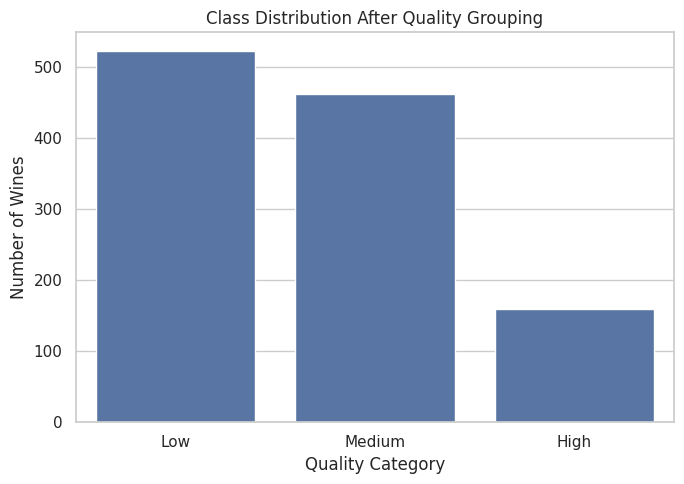

In [46]:
# Low: quality <= 5
# Medium: quality == 6
# High: quality >= 7

df["quality_group"] = np.select(
    [
        df["quality"] <= 5,
        df["quality"] == 6,
        df["quality"] >= 7
    ],
    [
        "Low",
        "Medium",
        "High"
    ],
    default="Unknown"
)

df = df[df["quality_group"] != "Unknown"].copy()

print("\nThree-class quality distribution:")
print(df["quality_group"].value_counts())

print("\nThree-class percentages:")
print(
    (df["quality_group"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="quality_group",
    order=["Low", "Medium", "High"]
)
plt.title("Class Distribution After Quality Grouping")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

# The classes may remain imbalanced even after grouping.
# Stratification preserves their proportions during splitting.

7. PREPARE FEATURES AND TARGET

In [47]:
X = df[features]
y = df["quality_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training samples: 914
Testing samples: 229

Training class proportions:
quality_group
Low       0.456
Medium    0.405
High      0.139
Name: proportion, dtype: float64

Testing class proportions:
quality_group
Low       0.459
Medium    0.402
High      0.140
Name: proportion, dtype: float64


8. DEFINING THREE CLASSIFICATION MODELS

In [48]:
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]),

    "SGD Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            loss="hinge",
            max_iter=2000,
            tol=1e-3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "SVC": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ])
}

9. TRAINING AND EVALUATING ALL THREE MODELS


Random Forest
Accuracy: 0.6900
Weighted Precision: 0.6935
Weighted Recall: 0.6900
Macro F1-Score: 0.6907
Weighted F1-Score: 0.6910

Classification Report:
              precision    recall  f1-score   support

         Low       0.75      0.73      0.74       105
      Medium       0.61      0.65      0.63        92
        High       0.75      0.66      0.70        32

    accuracy                           0.69       229
   macro avg       0.70      0.68      0.69       229
weighted avg       0.69      0.69      0.69       229



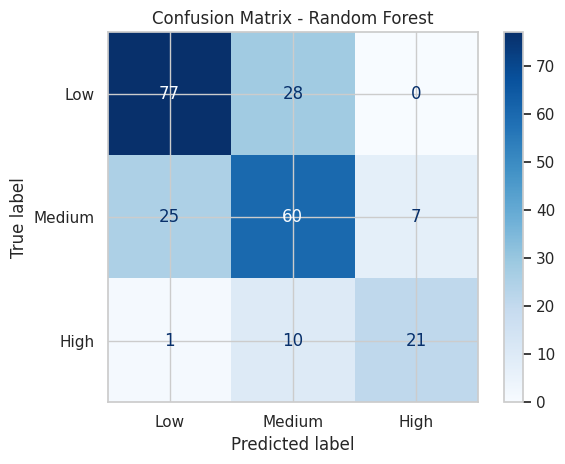


SGD Classifier
Accuracy: 0.5328
Weighted Precision: 0.5373
Weighted Recall: 0.5328
Macro F1-Score: 0.4834
Weighted F1-Score: 0.5340

Classification Report:
              precision    recall  f1-score   support

         Low       0.68      0.69      0.68       105
      Medium       0.46      0.41      0.43        92
        High       0.30      0.38      0.33        32

    accuracy                           0.53       229
   macro avg       0.48      0.49      0.48       229
weighted avg       0.54      0.53      0.53       229



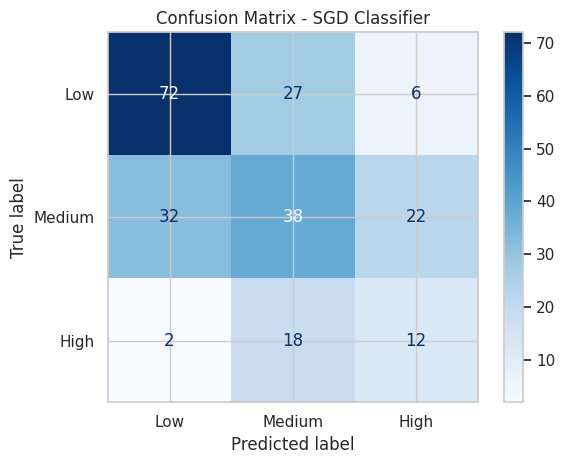


SVC
Accuracy: 0.6288
Weighted Precision: 0.6432
Weighted Recall: 0.6288
Macro F1-Score: 0.6124
Weighted F1-Score: 0.6277

Classification Report:
              precision    recall  f1-score   support

         Low       0.75      0.72      0.74       105
      Medium       0.58      0.47      0.52        92
        High       0.46      0.78      0.58        32

    accuracy                           0.63       229
   macro avg       0.60      0.66      0.61       229
weighted avg       0.64      0.63      0.63       229



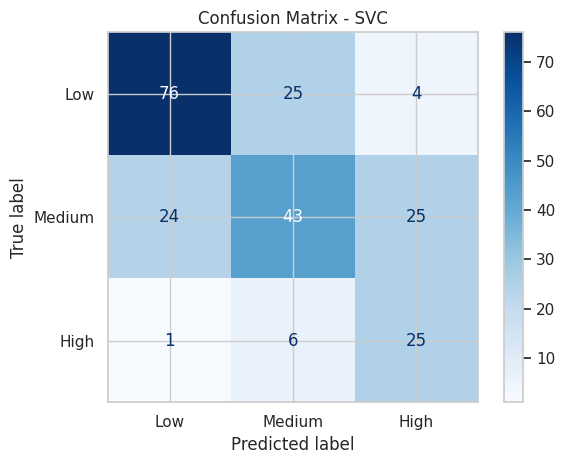

In [49]:
results = []
predictions = {}
class_labels = ["Low", "Medium", "High"]

for name, model in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Weighted Precision: {precision:.4f}")
    print(f"Weighted Recall: {recall:.4f}")
    print(f"Macro F1-Score: {macro_f1:.4f}")
    print(f"Weighted F1-Score: {weighted_f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            zero_division=0
        )
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

10. RANDOM FOREST FEATURE IMPORTANCE


Random Forest Feature Importance:
             Feature  Importance
             alcohol    0.167578
           sulphates    0.133364
    volatile acidity    0.113058
         citric acid    0.086904
total sulfur dioxide    0.084562
             density    0.081501
           chlorides    0.076836
       fixed acidity    0.069102
                  pH    0.067361
      residual sugar    0.060492
 free sulfur dioxide    0.059241


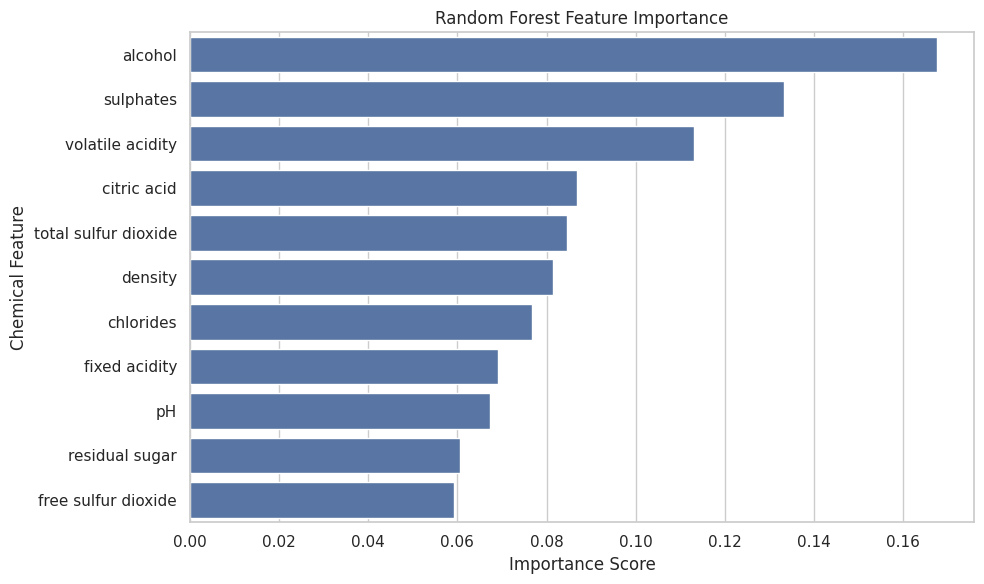

In [50]:
rf_model = models["Random Forest"]
rf_classifier = rf_model.named_steps["classifier"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_classifier.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nRandom Forest Feature Importance:")
print(importance.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.show()

11. SIDE BY SIDE - MODEL COMPARISON


Model Comparison:
                Accuracy  Weighted Precision  Weighted Recall  Macro F1  Weighted F1
Model                                                                               
Random Forest     0.6900              0.6935           0.6900    0.6907       0.6910
SGD Classifier    0.5328              0.5373           0.5328    0.4834       0.5340
SVC               0.6288              0.6432           0.6288    0.6124       0.6277


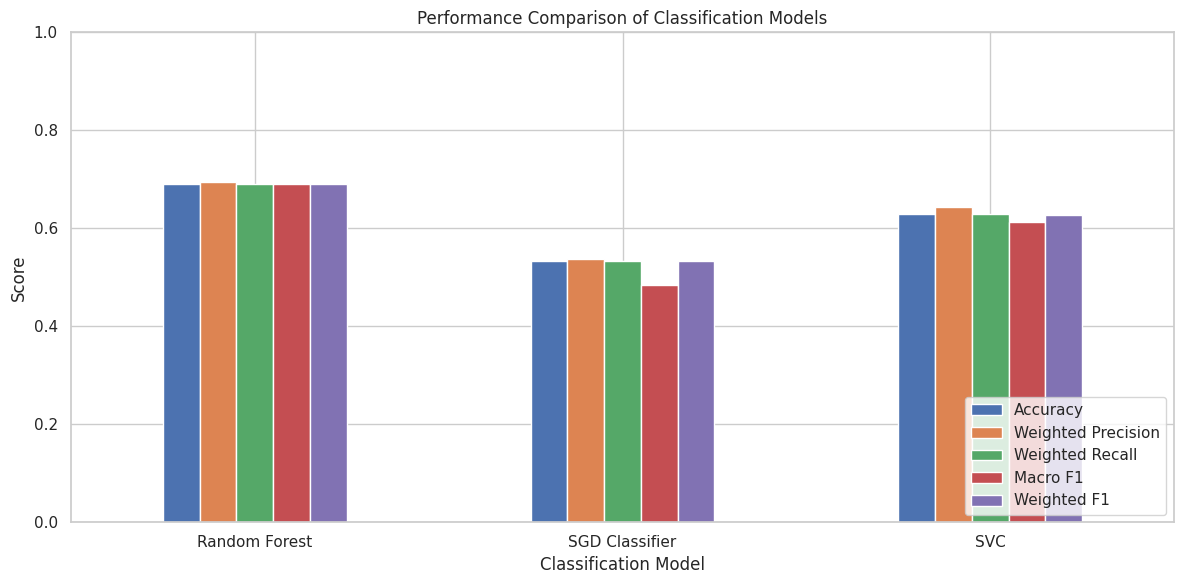

In [51]:
comparison = pd.DataFrame(results).set_index("Model")

print("\nModel Comparison:")
print(comparison.round(4).to_string())

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

12. FINAL MODEL SELECTION AND DEPLOYMENT RECOMMENDATION

In [52]:
# Macro F1 gives equal weight to each class, making it useful
# when low, medium and high quality groups are imbalanced.

best_model_name = comparison["Macro F1"].idxmax()
best_model = models[best_model_name]

print("\nBest model based on Macro F1:", best_model_name)
print("Macro F1-Score:", round(comparison.loc[best_model_name, "Macro F1"], 4))
print("Accuracy:", round(comparison.loc[best_model_name, "Accuracy"], 4))

print("\nDeployment Recommendation:")
print(
    f"{best_model_name} is the best candidate among the three models "
    "on this test split according to Macro F1. Before deployment, "
    "validate it further using cross-validation and assess its "
    "performance on each quality class."
)


Best model based on Macro F1: Random Forest
Macro F1-Score: 0.6907
Accuracy: 0.69

Deployment Recommendation:
Random Forest is the best candidate among the three models on this test split according to Macro F1. Before deployment, validate it further using cross-validation and assess its performance on each quality class.


13. EXAMPLE PREDICTION

In [53]:
sample_wine = pd.DataFrame([{
    "fixed acidity": 7.0,
    "volatile acidity": 0.27,
    "citric acid": 0.36,
    "residual sugar": 20.7,
    "chlorides": 0.045,
    "free sulfur dioxide": 45.0,
    "total sulfur dioxide": 170.0,
    "density": 1.001,
    "pH": 3.0,
    "sulphates": 0.45,
    "alcohol": 8.8
}])

predicted_quality = best_model.predict(sample_wine)[0]

print("\nExample Wine Prediction:", predicted_quality)


Example Wine Prediction: Low
